<a href="https://colab.research.google.com/github/JuanSilva085/Big-Data-Project/blob/main/BigData_trabalho.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [5]:
arquivos_csv = ["furtos.csv", "cvli.csv"]

In [ ]:
df = pd.concat([pd.read_csv(arquivo, encoding="latin1", sep=",") for arquivo in arquivos_csv])

In [ ]:
display(df.columns)
display(df.head())

Index(['AIS', 'Município', 'Dia da Semana', 'Data', 'Hora', 'Natureza',
       'Meio Empregado', 'Gênero', 'Idade da Vítima', 'Escolaridade da Vítima',
       'Raça da Vítima'],
      dtype='object')

,AIS,Município,Dia da Semana,Data,Hora,Natureza,Meio Empregado,Gênero,Idade da Vítima,Escolaridade da Vítima,Raça da Vítima
0,AIS 01,Fortaleza,Quarta,1/1/2025,00:00:00,NaN,NaN,NaN,NaN,NaN,NaN
1,AIS 01,Fortaleza,Quarta,1/1/2025,00:00:00,NaN,NaN,NaN,NaN,NaN,NaN
2,AIS 01,Fortaleza,Quarta,1/1/2025,00:00:00,NaN,NaN,NaN,NaN,NaN,NaN
3,AIS 10,Fortaleza,Quarta,1/1/2025,00:00:00,NaN,NaN,NaN,NaN,NaN,NaN
4,AIS 19,Juazeiro do Norte,Quarta,1/1/2025,00:00:00,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 43984 entries, 0 to 2522
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   AIS                     43984 non-null  object
 1   Município               43984 non-null  object
 2   Dia da Semana           43984 non-null  object
 3   Data                    43984 non-null  object
 4   Hora                    43984 non-null  object
 5   Natureza                2523 non-null   object
 6   Meio Empregado          2523 non-null   object
 7   Gênero                  2523 non-null   object
 8   Idade da Vítima         2523 non-null   object
 9   Escolaridade da Vítima  2523 non-null   object
 10  Raça da Vítima          2523 non-null   object
dtypes: object(11)
memory usage: 4.0+ MB


In [8]:
#junta os dados de furtos e crimes violentos, arruma as datas e descobre quantos desses eventos aconteceram em cada dia da semana.
df_furtos = pd.read_csv("furtos.csv", encoding="latin1", sep=",")
df_cvli = pd.read_csv("cvli.csv", encoding="latin1", sep=",")

df = pd.concat([df_furtos, df_cvli], ignore_index=True)

#converte a coluna 'Data' para o tipo Datetime
df['Data'] = pd.to_datetime(df['Data'], format='%m/%d/%Y', errors='coerce')

#extrai o 'Ano' e o 'Mes' a coluna 'Data' e cria as colunas (corrigido para .dt.year)
df['Ano'] = df['Data'].dt.year
df['Mes'] = df['Data'].dt.month

#agrupa por 'Dia da Semana' e conta as ocorrências
contagem_dias = df.groupby("Dia da Semana").size()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

arquivos_csv = ["furtos.csv", "cvli.csv"]

#junta os dados de furtos e crimes violentos, arruma as datas e descobre quantos desses eventos aconteceram em cada dia da semana.
df_furtos = pd.read_csv("furtos.csv", encoding="latin1", sep=",")
df_cvli = pd.read_csv("cvli.csv", encoding="latin1", sep=",")

df = pd.concat([df_furtos, df_cvli], ignore_index=True)

df['Data'] = pd.to_datetime(df['Data'], format='%m/%d/%Y', errors='coerce')

df['Ano'] = df['Data'].dt.year
df['Mes'] = df['Data'].dt.month

contagem_dias = df.groupby("Dia da Semana").size()

In [ ]:
df['Data'] = pd.to_datetime(df['Data'], format='%m/%d/%Y', errors='coerce')
df['Ano'] = df['Data'].dt.year
df['Mes'] = df['Data'].dt.month
furtos_mensal = df.groupby(["Ano", "Mes"]).size()
display(furtos_mensal)

Ano   Mes
2025  1      4765
      2      4826
      3      4780
      4      4557
      5      4900
      6      5184
      7      5181
      8      4812
      9      4695
      10      284
dtype: int64

In [ ]:
#filtra os dados para encontrar apenas os furtos, agrupa por dia da semana e conta quantos furtos aconteceram em cada dia.
df_furtos_ocorrencias = df[df['Natureza'].isna()]

contagem_dias_furtos = df_furtos_ocorrencias.groupby("Dia da Semana").size()

display(contagem_dias_furtos)

,0
Dia da Semana,
Domingo,5347
Quarta,5140
Quinta,5110
Segunda,5041
Sexta,5463
Sábado,5905
Terça,5029


In [ ]:
sns.set_style('darkgrid') #estilização

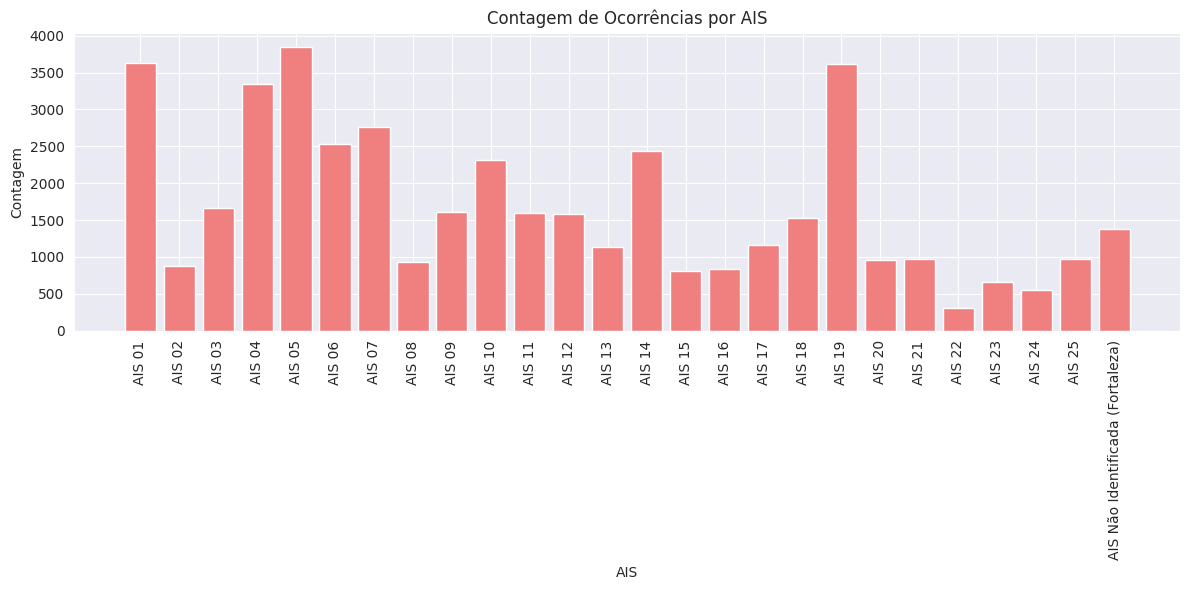

In [ ]:
#As AISs são divisões territoriais feitas para organizar ações de segurança pública de maneira integrada.

#Gráfico de barras para a Contagem de ocorrências por AIS (dados combinados)

contagem_ais = df.groupby("AIS").size()

plt.figure(figsize=(12, 6))

#contagem_ais.index (valores de AIS)
#contagem_ais.values (contagem para cada AIS)
plt.bar(contagem_ais.index, contagem_ais.values, color='lightcoral')

plt.title('Contagem de Ocorrências por AIS')
plt.xlabel('AIS')
plt.ylabel('Contagem')

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

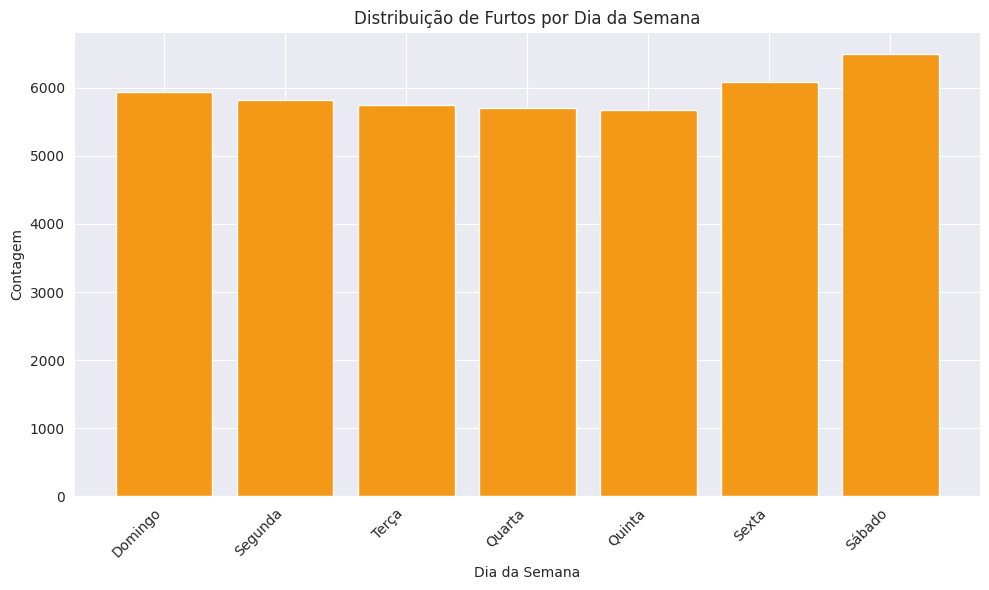

In [ ]:
#Gráfico de barras para a distribuição de Furtos por Dia da Semana
df_furtos_ocorrencias = df[df['Natureza'].isna()]
contagem_dias_furtos = df_furtos_ocorrencias.groupby("Dia da Semana").size()
ordem_dias = ['Domingo' , 'Segunda', 'Terça', 'Quarta', 'Quinta', 'Sexta', 'Sábado']
contagem_dias_furtos_reordenada = contagem_dias_furtos.reindex(ordem_dias)

plt.figure(figsize=(10, 6))

plt.bar(contagem_dias_furtos_reordenada.index, contagem_dias_furtos_reordenada.values, color='#f39917')

plt.title('Distribuição de Furtos por Dia da Semana')
plt.xlabel('Dia da Semana')
plt.ylabel('Contagem')

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

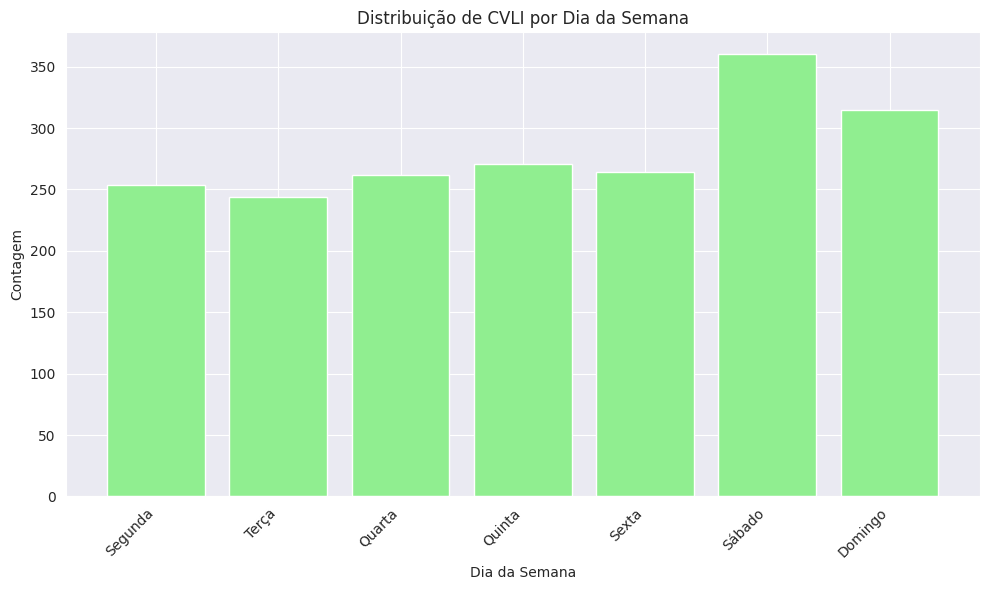

In [ ]:
#Gráfico de barras para a distribuição de CVLI por Dia da Semana
df_cvli_ocorrencias = df[df['Natureza'].isin(['FEMINICÍDIO',
                                              'HOMICIDIO DOLOSO', 'LESAO CORPORAL SEGUIDA DE MORTE', 'ROUBO SEGUIDO DE MORTE (LATROCINIO)'])]

#agrupar por 'Dia da Semana' e contar as ocorrências de CVLI
contagem_dias_cvli = df_cvli_ocorrencias.groupby("Dia da Semana").size()

ordem_dias = ['Segunda', 'Terça', 'Quarta', 'Quinta', 'Sexta', 'Sábado', 'Domingo']
contagem_dias_cvli_reordenada = contagem_dias_cvli.reindex(ordem_dias)

plt.figure(figsize=(10, 6))
plt.bar(contagem_dias_cvli_reordenada.index, contagem_dias_cvli_reordenada.values, color='lightgreen')

plt.title('Distribuição de CVLI por Dia da Semana')
plt.xlabel('Dia da Semana')
plt.ylabel('Contagem')

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

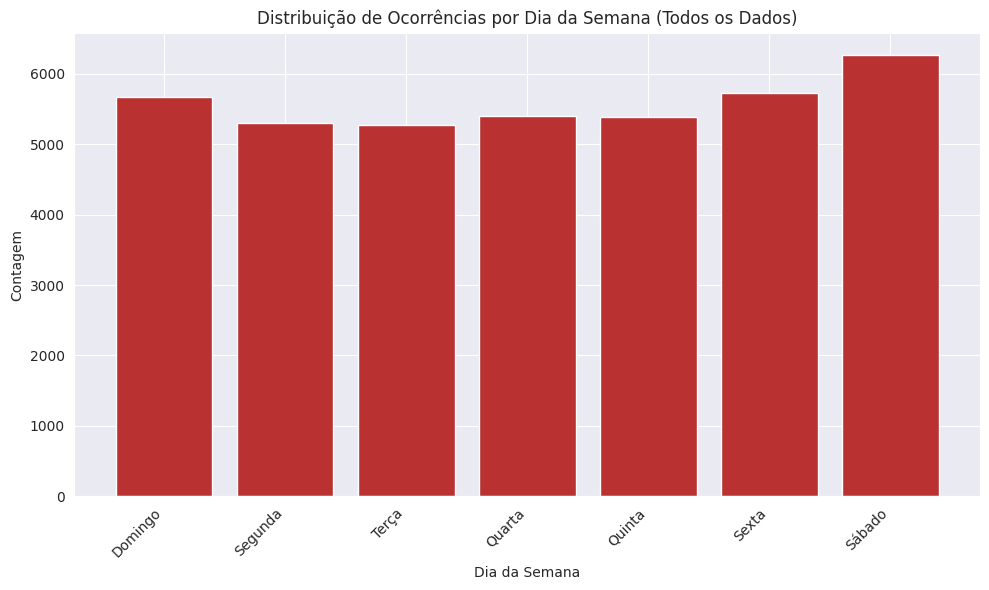

In [ ]:
#Gráfico de barras para a distribuição de ocorrências por Dia da Semana (dados combinados)

ordem_dias = ['Domingo' , 'Segunda', 'Terça', 'Quarta', 'Quinta', 'Sexta', 'Sábado']
contagem_dias_reordenada = contagem_dias.reindex(ordem_dias)

plt.figure(figsize=(10, 6))

plt.bar(contagem_dias_reordenada.index, contagem_dias_reordenada.values, color='#b93131')

plt.title('Distribuição de Ocorrências por Dia da Semana (Todos os Dados)')
plt.xlabel('Dia da Semana')
plt.ylabel('Contagem')

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

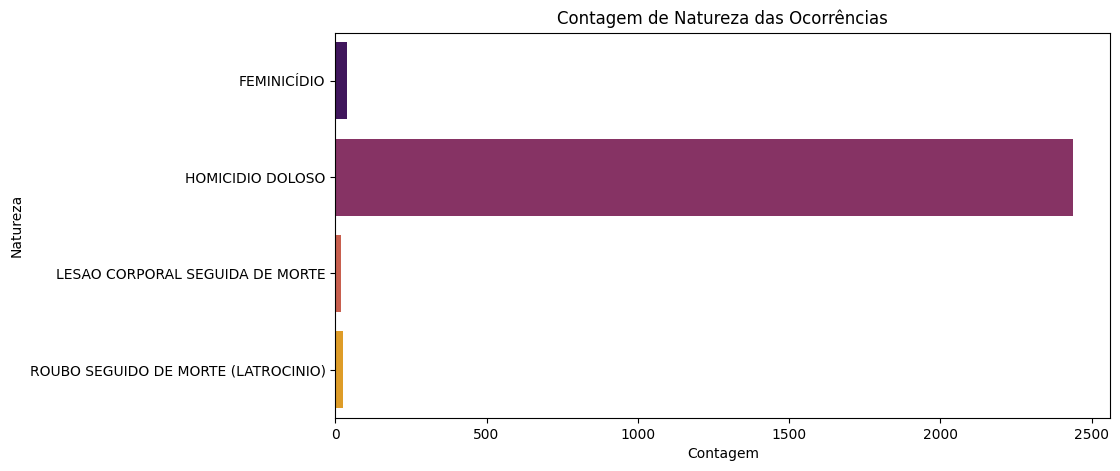

In [13]:
#calcular contagem_natureza
contagem_natureza = df.groupby('Natureza').size()

#cria um gráfico de barras horizontais
#contagem_natureza.index (os tipos de Natureza das ocorrências)
#contagem_natureza.values (contagem para cada Natureza)

plt.figure(figsize=(10, 5))
sns.barplot(
    x=contagem_natureza.values,
    y=contagem_natureza.index,
    palette='inferno',
    hue=contagem_natureza.index,
    legend=False
)

plt.title('Contagem de Natureza das Ocorrências')
plt.xlabel('Contagem')
plt.ylabel('Natureza')
plt.show()

In [ ]:
contagem_natureza = df.groupby('Natureza').size()
display(contagem_natureza)

,0
Natureza,
FEMINICÍDIO,34
HOMICIDIO DOLOSO,1905
LESAO CORPORAL SEGUIDA DE MORTE,16
ROUBO SEGUIDO DE MORTE (LATROCINIO),15


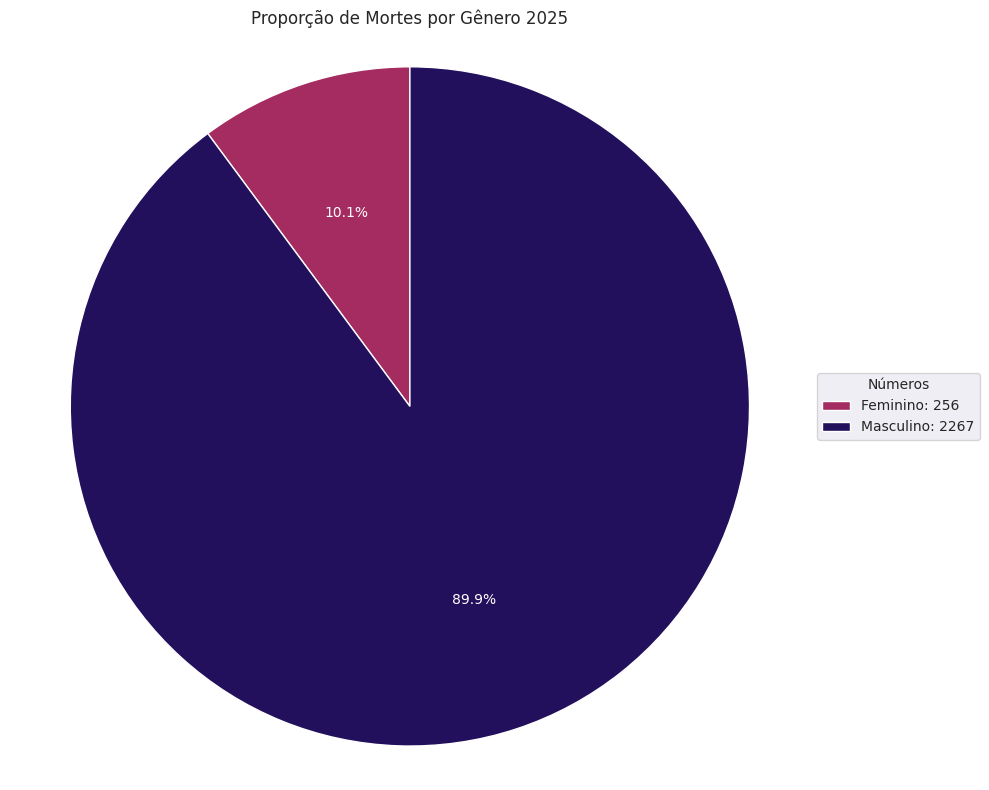

In [ ]:
df_mortes = df[df['Natureza'].isin(['FEMINICÍDIO', 'HOMICIDIO DOLOSO', 'LESAO CORPORAL SEGUIDA DE MORTE', 'ROUBO SEGUIDO DE MORTE (LATROCINIO)'])]
contagem_genero_mortes = df_mortes.groupby('Gênero').size()


proporcao_mortes = contagem_genero_mortes / contagem_genero_mortes.sum()

plt.figure(figsize=(10, 8))


def func(pct, allvals):
    absolute = int(round(pct/100.*sum(allvals)))
    return f"{pct:.1f}%"

plt.pie(proporcao_mortes,
        labels=None,
        autopct=lambda pct: func(pct, contagem_genero_mortes),
        startangle=90,
        colors=['#a52c60' if label == 'Feminino' else '#23105C' for label in proporcao_mortes.index],
        textprops={'color': 'white'})

plt.title('Proporção de Mortes por Gênero 2025')
plt.axis('equal')


legend_labels = [f'{label}: {count}' for label, count in contagem_genero_mortes.items()]

plt.legend(legend_labels, title="Números", loc="center left", bbox_to_anchor=(1, 0, 0.5, 1))

plt.tight_layout()
plt.show()

Valores nulos na coluna Idade da Vítima:  41461


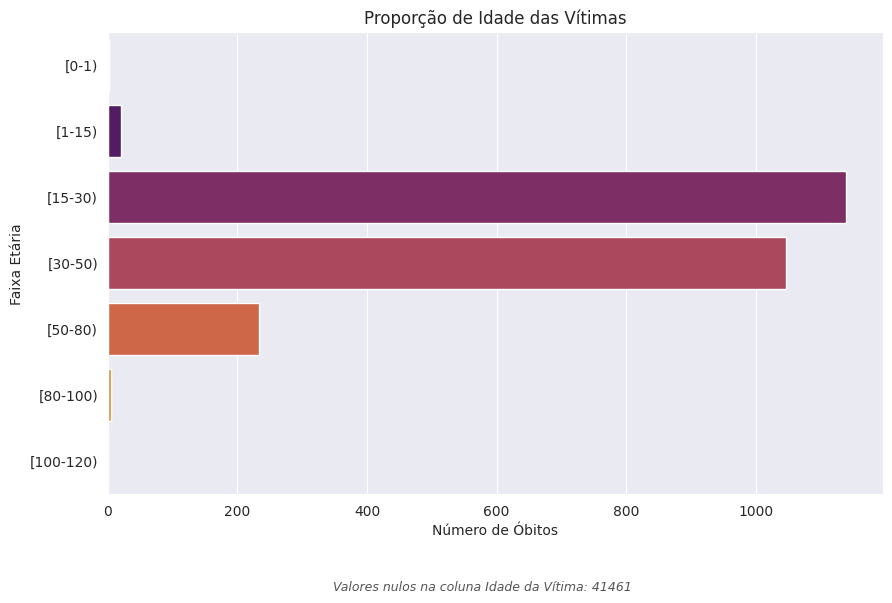

In [ ]:
#PROPORÇÃO POR IDADE

print("Valores nulos na coluna Idade da Vítima: ", df['Idade da Vítima'].isna().sum())

df_mortes = df[df['Natureza'].isin(['FEMINICÍDIO', 'HOMICIDIO DOLOSO', 'LESAO CORPORAL SEGUIDA DE MORTE', 'ROUBO SEGUIDO DE MORTE (LATROCINIO)'])]
df_clean_deaths = df_mortes.copy()

df_clean_deaths['Idade da Vítima_ANOS'] = pd.to_numeric(df_clean_deaths['Idade da Vítima'], errors='coerce')

df_clean_deaths = df_clean_deaths.dropna(subset=['Idade da Vítima_ANOS']).copy()

bins = [0, 1, 15, 30, 50, 80, 100, 120]
labels = ['[0-1)', '[1-15)', '[15-30)', '[30-50)', '[50-80)', '[80-100)', '[100-120)']


df_clean_deaths['FAIXA_ETARIA'] = pd.cut(df_clean_deaths['Idade da Vítima_ANOS'], bins=bins, labels=labels, right = False)

mortes_por_idade = df_clean_deaths['FAIXA_ETARIA'].value_counts().sort_index()

plt.figure(figsize = (10, 6))
sns.barplot(
    x=mortes_por_idade.values,
    y=mortes_por_idade.index,
    palette='inferno',
    hue=mortes_por_idade.index,
    legend=False
)


plt.figtext(
    0.5,
    -0.05,
    f"Valores nulos na coluna Idade da Vítima: {df['Idade da Vítima'].isna().sum()}",
    ha = 'center',
    fontsize = 9,
    style = 'italic',
    color = '#555555'
)

plt.title('Proporção de Idade das Vítimas')
plt.xlabel('Número de Óbitos')
plt.ylabel('Faixa Etária')

plt.savefig('mortali.png', dpi=300, bbox_inches='tight')

plt.show()

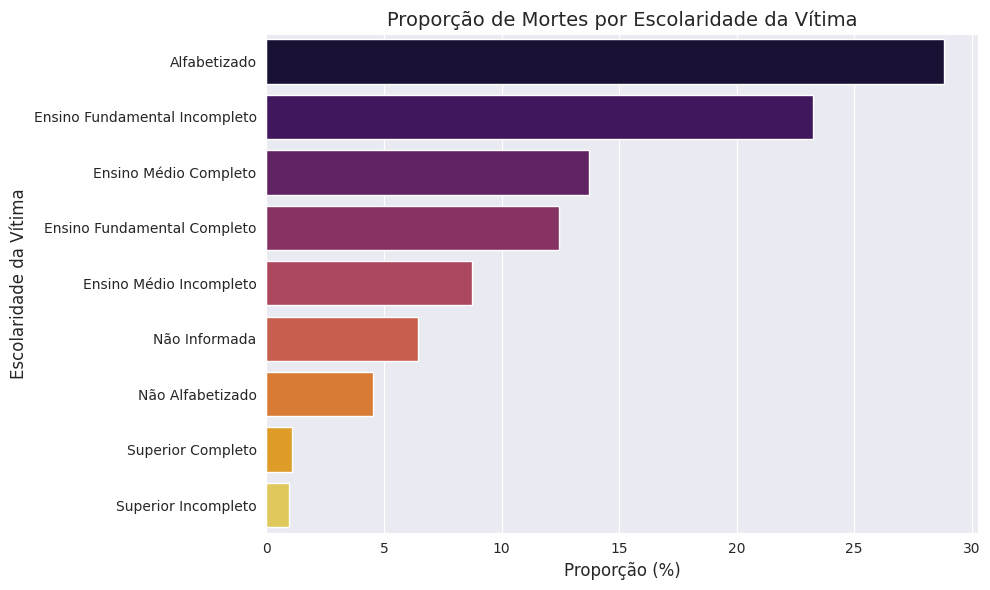

In [ ]:
# PROPORÇÃO POR ESCOLARIDADE

df_deaths_escolaridade = df_mortes.copy()

proporcao_escolaridade = df_deaths_escolaridade['Escolaridade da Vítima'].value_counts(normalize=True) * 100

proporcao_escolaridade = proporcao_escolaridade.sort_values(ascending=False)


plt.figure(figsize=(10, 6))

sns.barplot(
    x=proporcao_escolaridade.values,
    y=proporcao_escolaridade.index,
    palette='inferno',
    hue=proporcao_escolaridade.index,
    legend=False
)

plt.title('Proporção de Mortes por Escolaridade da Vítima', fontsize=14)
plt.xlabel('Proporção (%)', fontsize=12)
plt.ylabel('Escolaridade da Vítima', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
df_furtos_demographics = df[df['Natureza'].isna()]

contagem_genero_furtos = df_furtos_demographics['Gênero'].value_counts()
contagem_idade_furtos = df_furtos_demographics['Idade da Vítima'].value_counts()

display(contagem_genero_furtos)
display(contagem_idade_furtos)

,count
Gênero,


,count
Idade da Vítima,


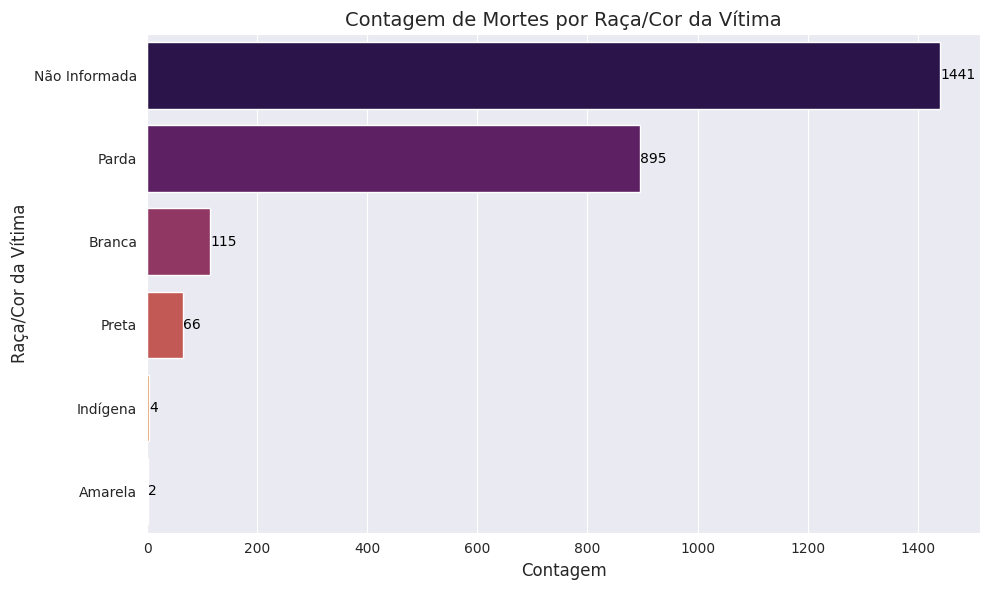

In [ ]:
df_deaths_raca = df_mortes.copy()

contagem_raca = df_deaths_raca['Raça da Vítima'].value_counts()
contagem_raca = contagem_raca.sort_values(ascending=False)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=contagem_raca.values,
    y=contagem_raca.index,
    palette='inferno',
    hue=contagem_raca.index,
    legend=False
)

for p in ax.patches:
    count = int(p.get_width())
    x = p.get_width()
    y = p.get_y() + p.get_height() / 2
    ax.annotate(count, (x, y), ha='left', va='center', fontsize=10, color='black')


plt.title('Contagem de Mortes por Raça/Cor da Vítima', fontsize=14)
plt.xlabel('Contagem', fontsize=12)
plt.ylabel('Raça/Cor da Vítima', fontsize=12)
plt.tight_layout()
plt.show()

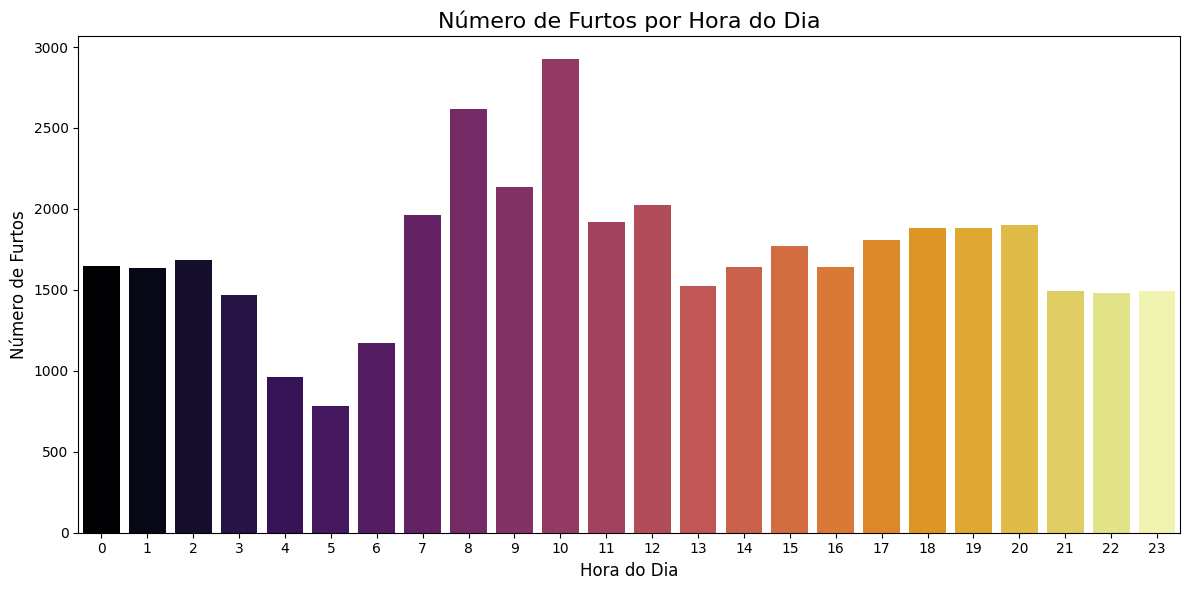

In [10]:
# Garante que as colunas de hora sejam extraídas usando o formato específico para evitar avisos
if 'Hora_ocorrencia' not in df.columns:
    df['Hora_ocorrencia'] = pd.to_datetime(df['Hora'], format='%H:%M:%S', errors='coerce').dt.hour

df_filtered_hora = df.dropna(subset=['Hora_ocorrencia']).copy()

# HORA FURTOS
df_furtos_ocorrencias_hora = df_filtered_hora[df_filtered_hora['Natureza'].isna()]
contagem_hora_furtos = df_furtos_ocorrencias_hora.groupby('Hora_ocorrencia').size().reset_index(name='Contagem')

plt.figure(figsize=(12, 6))
sns.barplot(
    x='Hora_ocorrencia',
    y='Contagem',
    data=contagem_hora_furtos,
    palette='inferno',
    hue='Hora_ocorrencia',
    legend=False
)

plt.title('Número de Furtos por Hora do Dia', fontsize=16)
plt.xlabel('Hora do Dia', fontsize=12)
plt.ylabel('Número de Furtos', fontsize=12)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

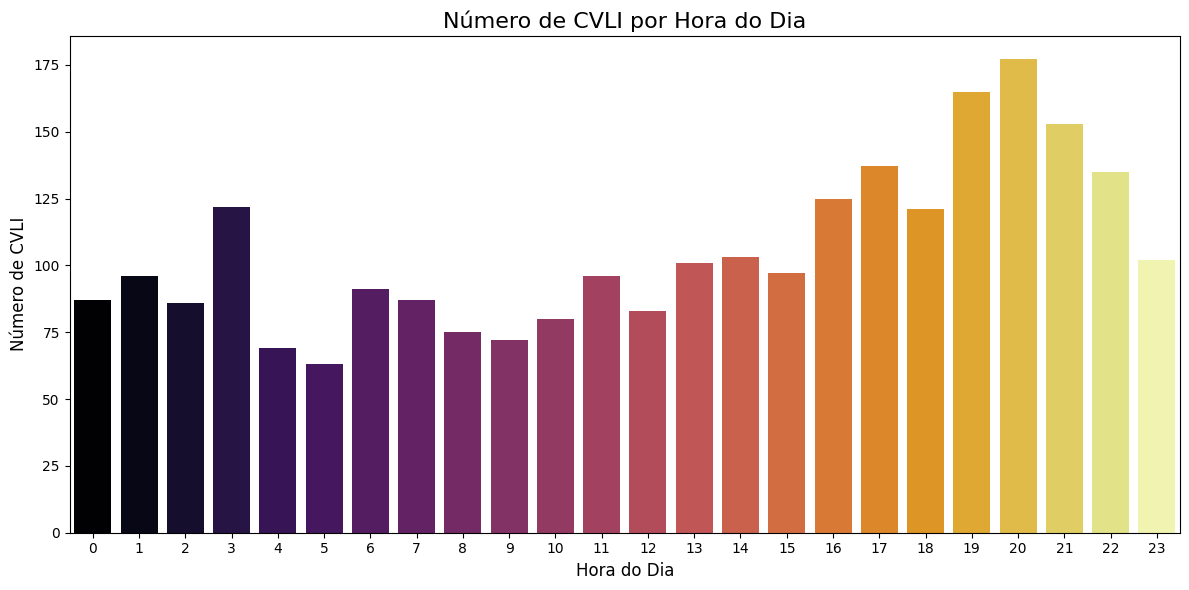

In [11]:
# HORA CRIMES VIOLENTOS
df_cvli_ocorrencias_hora = df_filtered_hora[df_filtered_hora['Natureza'].isin(['FEMINICÍDIO', 'HOMICIDIO DOLOSO', 'LESAO CORPORAL SEGUIDA DE MORTE', 'ROUBO SEGUIDO DE MORTE (LATROCINIO)'])]
contagem_hora_cvli = df_cvli_ocorrencias_hora.groupby('Hora_ocorrencia').size().reset_index(name='Contagem')

plt.figure(figsize=(12, 6))
sns.barplot(
    x='Hora_ocorrencia',
    y='Contagem',
    data=contagem_hora_cvli,
    palette='inferno',
    hue='Hora_ocorrencia',
    legend=False
)

plt.title('Número de CVLI por Hora do Dia', fontsize=16)
plt.xlabel('Hora do Dia', fontsize=12)
plt.ylabel('Número de CVLI', fontsize=12)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

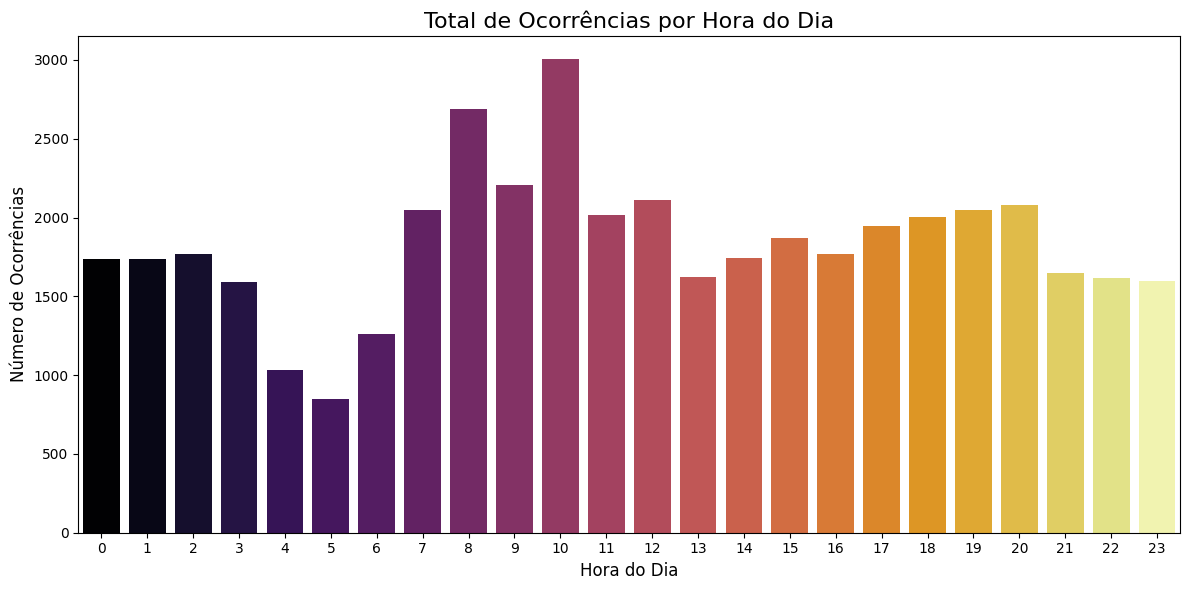

In [12]:
# HORA OCORRENCIAS FURTOS/CRIMES VIOLENTOS
# Utiliza o df_filtered_hora otimizado já criado anteriormente
contagem_hora = df_filtered_hora.groupby('Hora_ocorrencia').size().reset_index(name='Contagem')

plt.figure(figsize=(12, 6))
sns.barplot(
    x='Hora_ocorrencia',
    y='Contagem',
    data=contagem_hora,
    palette='inferno',
    hue='Hora_ocorrencia',
    legend=False
)

plt.title('Total de Ocorrências por Hora do Dia', fontsize=16)
plt.xlabel('Hora do Dia', fontsize=12)
plt.ylabel('Número de Ocorrências', fontsize=12)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
df_mortes = df[df['Natureza'].isin(['FEMINICÍDIO', 'HOMICIDIO DOLOSO', 'LESAO CORPORAL SEGUIDA DE MORTE', 'ROUBO SEGUIDO DE MORTE (LATROCINIO)'])]
contagem_genero_mortes = df_mortes.groupby('Gênero').size()